# Demo 9 - Classifier-Free Guidance

In [1]:
from datetime import datetime

In [2]:
import json

In [3]:
import os

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [6]:
from tqdm.auto import tqdm

In [7]:
import torch
from torch import nn
from torch.nn import functional as F
from torch import optim
from torch.utils.data import DataLoader

In [8]:
from torchvision import datasets
from torchvision.transforms import v2, InterpolationMode

In [9]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

### 1. Diffusion Steps

In [10]:
NUM_DIFFUSION_STEPS = 1000

In [11]:
BETA_START = 1e-4
BETA_END = 0.02

In [12]:
betas = torch.linspace(BETA_START, BETA_END, NUM_DIFFUSION_STEPS, device=device)

In [13]:
alphas = 1 - betas

In [14]:
alpha_bars = torch.cumprod(alphas, dim=0)

In [15]:
sqrt_alpha_bars = torch.sqrt(alpha_bars)

In [16]:
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)

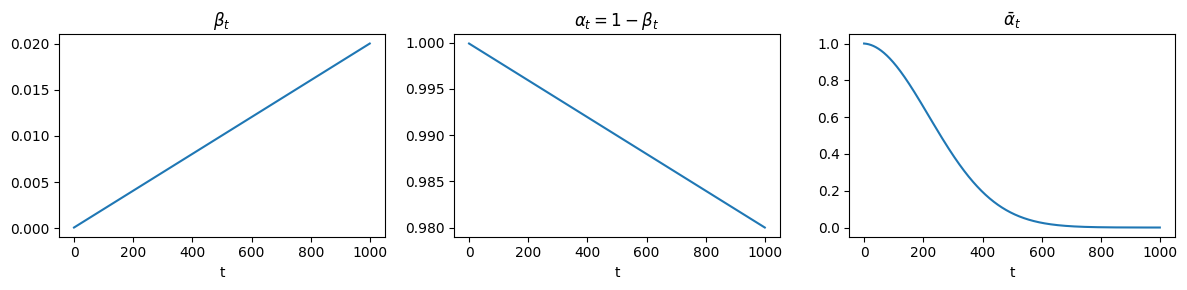

In [17]:
plt.figure(figsize=(12, 3))

plt.subplot(1, 3, 1)
plt.plot(betas.cpu().numpy())
plt.title(r"$\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 2)
plt.plot(alphas.cpu().numpy())
plt.title(r"$\alpha_t = 1-\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 3)
plt.plot(alpha_bars.cpu().numpy())
plt.title(r"$\bar{\alpha}_t$")
plt.xlabel("t")

plt.tight_layout()
plt.show()

In [18]:
# Forward Diffusion
def q_sample(x0, t, noise=None):
    # generate random gaussian noise with the same shape as img x0.
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    xt = sqrt_ab * x0 + sqrt_1mab * noise
    return xt, noise

In [19]:
# Noise Prediction Loss
mse = nn.MSELoss()

### 2. Model Setup

In [20]:
transform = v2.Compose([
    v2.Resize((64, 64), InterpolationMode.BICUBIC),
    v2.Grayscale(num_output_channels=1),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5,), (0.5,))   # map [0,1] -> [-1,1]
])

In [21]:
def denorm(x: torch.tensor) -> torch.tensor:
    return (x.clamp(-1, 1) + 1) / 2

In [22]:
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

In [23]:
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [24]:
class_names = train_dataset.classes

In [25]:
sample_image, sample_label = train_dataset[0]
sample_image = sample_image.to(device)

In [26]:
sample_image.shape

torch.Size([1, 64, 64])

In [27]:
timesteps = np.array([1, 200, 400, 600, 800, 1000])

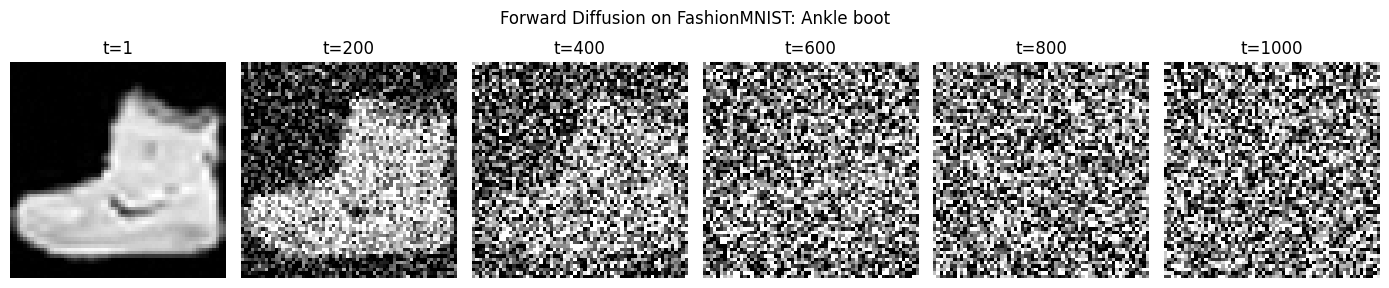

In [28]:
fig, axes = plt.subplots(1, len(timesteps), figsize=(14, 3))
for ax, t in zip(axes, timesteps):
    t_tensor = torch.tensor([t - 1], device=device)
    xt, _ = q_sample(sample_image, t_tensor)
    ax.imshow(denorm(xt[0, 0]).detach().cpu(), cmap="gray")
    ax.set_title(f"t={t}")
    ax.axis("off")

plt.suptitle(f"Forward Diffusion on FashionMNIST: {class_names[sample_label]}")
plt.tight_layout()
plt.show()

In [29]:
# Sinusoidal Time Embedding
class TimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        embeddings = np.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=t.device) * -embeddings)
        embeddings = t[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

In [30]:
# Residual Blocks with GroupNorm and SiLU
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, time_channels: int):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)

        self.time_proj = nn.Linear(time_channels, out_channels)

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)

        self.act = nn.SiLU()

    def forward(self, x, t_emb):
        h = self.conv1(self.act(self.norm1(x)))

        time_emb_proj = self.time_proj(self.act(t_emb))[:, :, None, None]
        h = h + time_emb_proj

        h = self.conv2(self.act(self.norm2(h)))
        return h

In [31]:
# Self-attention
class SelfAttention(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.mha = nn.MultiheadAttention(channels, num_heads=4, batch_first=True)
        self.norm = nn.GroupNorm(8, num_channels=channels)

        self.ff = nn.Sequential(
            nn.LayerNorm(channels),
            nn.Linear(channels, channels),
            nn.SiLU(),
            nn.Linear(channels, channels),
        )

    def forward(self, x):
        b, c, h, w = x.shape

        x_flat = x.view(b, c, -1).permute(0, 2, 1)

        x_norm = self.norm(x_flat.permute(0, 2, 1)).permute(0, 2, 1)
        attn_out, _ = self.mha(x_norm, x_norm, x_norm)
        x_flat = x_flat + attn_out

        x_flat = x_flat + self.ff(x_flat)

        return x_flat.permute(0, 2, 1).view(b, c, h, w)

In [32]:
# Bottleneck
class BottleNeck(nn.Module):
    def __init__(self, channels: int, time_channels: int):
        super().__init__()

        self.block1 = ResidualBlock(channels, channels, time_channels)
        self.attn = SelfAttention(channels)
        self.block2 = ResidualBlock(channels, channels, time_channels)

    def forward(self, x, t_emb):
        x = self.block1(x, t_emb)
        x = self.attn(x)
        x = self.block2(x, t_emb)
        return x

In [33]:
class EncoderBlock(nn.Module):
    def __init__(self, input_channels: int, output_channels: int, time_channels: int):
        super().__init__()
        self.input_channels = input_channels
        self.output_channels = output_channels
        self.time_channels = time_channels

        self.block = ResidualBlock(self.input_channels, self.output_channels, self.time_channels)
        self.pool = nn.MaxPool2d((2, 2))

    def forward(self, x, t_emb):
        x = self.block(x, t_emb)
        p = self.pool(x)
        return x, p  # Return both for the skip connection

In [34]:
class DecoderBlock(nn.Module):
    def __init__(self, input_channels: int, output_channels: int, time_channels: int):
        super().__init__()
        self.up = nn.Sequential(
            nn.UpsamplingBilinear2d(scale_factor=2),
            nn.Conv2d(input_channels, input_channels, kernel_size=3, padding=1)
        )

        self.block = ResidualBlock(2 * input_channels, output_channels, time_channels)

    def forward(self, x, skip, t_emb):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)  # Skip Connection
        x = self.block(x, t_emb)
        return x

In [35]:
class UNet(nn.Module):
    def __init__(self, base_channels: int = 64):
        super().__init__()
        time_dim = base_channels * 4

        # Classifier-Free Guidance
        self.label_embedding = nn.Embedding(
            num_embeddings=len(class_names) + 1,
            embedding_dim=time_dim
        )

        # Time embedding + MLP
        self.time_mlp = nn.Sequential(
            TimeEmbedding(base_channels),
            nn.Linear(base_channels, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.init_conv = nn.Conv2d(1, base_channels, kernel_size=3, padding='same')

        self.e1 = EncoderBlock(base_channels, base_channels, time_dim)
        self.e2 = EncoderBlock(base_channels, base_channels * 2, time_dim)
        self.attn1 = SelfAttention(base_channels * 2)
        self.e3 = EncoderBlock(base_channels * 2, base_channels * 4, time_dim)

        self.bottleneck = BottleNeck(base_channels * 4, time_dim)

        self.d1 = DecoderBlock(base_channels * 4, base_channels * 2, time_dim)
        self.attn2 = SelfAttention(base_channels * 2)
        self.d2 = DecoderBlock(base_channels * 2, base_channels, time_dim)
        self.d3 = DecoderBlock(base_channels, base_channels, time_dim)

        self.final_conv = nn.Conv2d(base_channels, 1, kernel_size=1)

    def forward(self, x, t, y=None):

        t_emb = self.time_mlp(t)

        if y is None:
            y = torch.full((x.shape[0],), 10, device=x.device, dtype=torch.long)

        # Combining the label and time embeddings
        t_emb += self.label_embedding(y)

        x = self.init_conv(x)
        s1, p1 = self.e1(x, t_emb)
        s2, p2 = self.e2(p1, t_emb)
        p2 = self.attn1(p2)
        s3, p3 = self.e3(p2, t_emb)

        b = self.bottleneck(p3, t_emb)

        x = self.d1(b, s3, t_emb)
        x = self.attn2(x)
        x = self.d2(x, s2, t_emb)
        x = self.d3(x, s1, t_emb)

        out = self.final_conv(x)
        return out

In [36]:
model = UNet().to(device)

### 3. Training

In [37]:
NUM_EPOCHS = 50

In [38]:
BATCH_SIZE = 1000

In [39]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE)

In [40]:
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

In [41]:
optimizer = optim.Adam(model.parameters(), lr=2e-5)

In [42]:
drop_label_probability = 0.1

In [43]:
training_losses = []
testing_losses = []

In [44]:
for epoch in tqdm(range(NUM_EPOCHS), desc="Epoch"):
    epoch_training_loss = 0
    epoch_test_loss = 0

    model.train()
    for step, (images, labels) in enumerate(tqdm(train_loader, desc="Training", leave=False)):
        images = images.to(device)
        labels = labels.to(device)
        batch_size = images.shape[0]

        # Drop labels w/ probability
        if torch.rand(1) < drop_label_probability:
            y = None
        else:
            y = labels

        t = torch.randint(0, NUM_DIFFUSION_STEPS, (batch_size,), device=device)

        x_t, noise_target = q_sample(images, t)

        noise_pred = model(x_t, t, y)

        loss = mse(noise_pred, noise_target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_training_loss += loss.item()

    training_losses.append(epoch_training_loss / len(train_loader))

    with torch.no_grad():
        model.eval()
        for step, (images, labels) in enumerate(tqdm(test_loader, desc="Test", leave=False)):
            images = images.to(device)
            labels = labels.to(device)
            batch_size = images.shape[0]

            # Drop labels w/ probability
            if torch.rand(1) < drop_label_probability:
                y = None
            else:
                y = labels

            t = torch.randint(0, NUM_DIFFUSION_STEPS, (batch_size,), device=device)

            x_t, noise_target = q_sample(images, t)

            noise_pred = model(x_t, t, y)

            loss = mse(noise_pred, noise_target)

            epoch_test_loss += loss.item()

    testing_losses.append(epoch_test_loss / len(test_loader))

Epoch:   0%|          | 0/50 [00:00<?, ?it/s]

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Test:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Test:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/60 [00:00<?, ?it/s]

... (91 outputs left out)

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Test:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/60 [00:00<?, ?it/s]

Test:   0%|          | 0/10 [00:00<?, ?it/s]

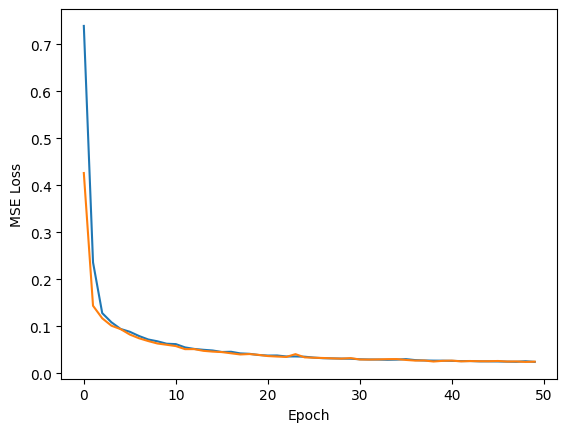

In [45]:
plt.plot(training_losses, label='Train')
plt.plot(testing_losses, label='Test')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.show()

### 4. Sampling

In [46]:
TIMESTEP_SAMPLE_FREQUENCY = 200

In [47]:
alpha_bars_prev = F.pad(alpha_bars, (1, 0), value=1)[:-1]

In [48]:
w = 3

In [49]:
torch.manual_seed(42)

In [50]:
target_classes = torch.arange(len(class_names)).to(device)

In [51]:
n_samples = len(target_classes)

In [52]:
intermediates = []

In [53]:
model.eval()
with torch.no_grad():
    x = torch.randn((n_samples, 1, 64, 64), device=device)
    intermediates.append((1000, denorm(x)))

    for timestep in tqdm(reversed(range(NUM_DIFFUSION_STEPS)), desc="Timestep", total=NUM_DIFFUSION_STEPS):
        t = torch.full((n_samples,), timestep, device=device, dtype=torch.long)

        eps_cond = model(x, t, target_classes)
        eps_uncond = model(x, t, None)

        predicted_noise = (1 + w) * eps_cond - w * eps_uncond

        alpha = alphas[t].view(-1, 1, 1, 1)
        alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)
        alpha_bar_prev = alpha_bars_prev[t].view(-1, 1, 1, 1)
        sqrt_one_minus_alpha_bar = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
        beta = betas[t].view(-1, 1, 1, 1)

        mean = (1 / torch.sqrt(alpha)) * (
            x - ((1 - alpha) / sqrt_one_minus_alpha_bar) * predicted_noise
        )

        if timestep > 0:
            noise = torch.randn_like(x)
            # sigma = torch.sqrt(beta)
            sigma = torch.sqrt(beta * (1 - alpha_bar_prev) / (1 - alpha_bar))
            x = mean + sigma * noise
        else:
            x = mean

        if timestep % TIMESTEP_SAMPLE_FREQUENCY == 0:
            intermediates.append((timestep, denorm(x)))

x = denorm(x)

Timestep:   0%|          | 0/1000 [00:00<?, ?it/s]

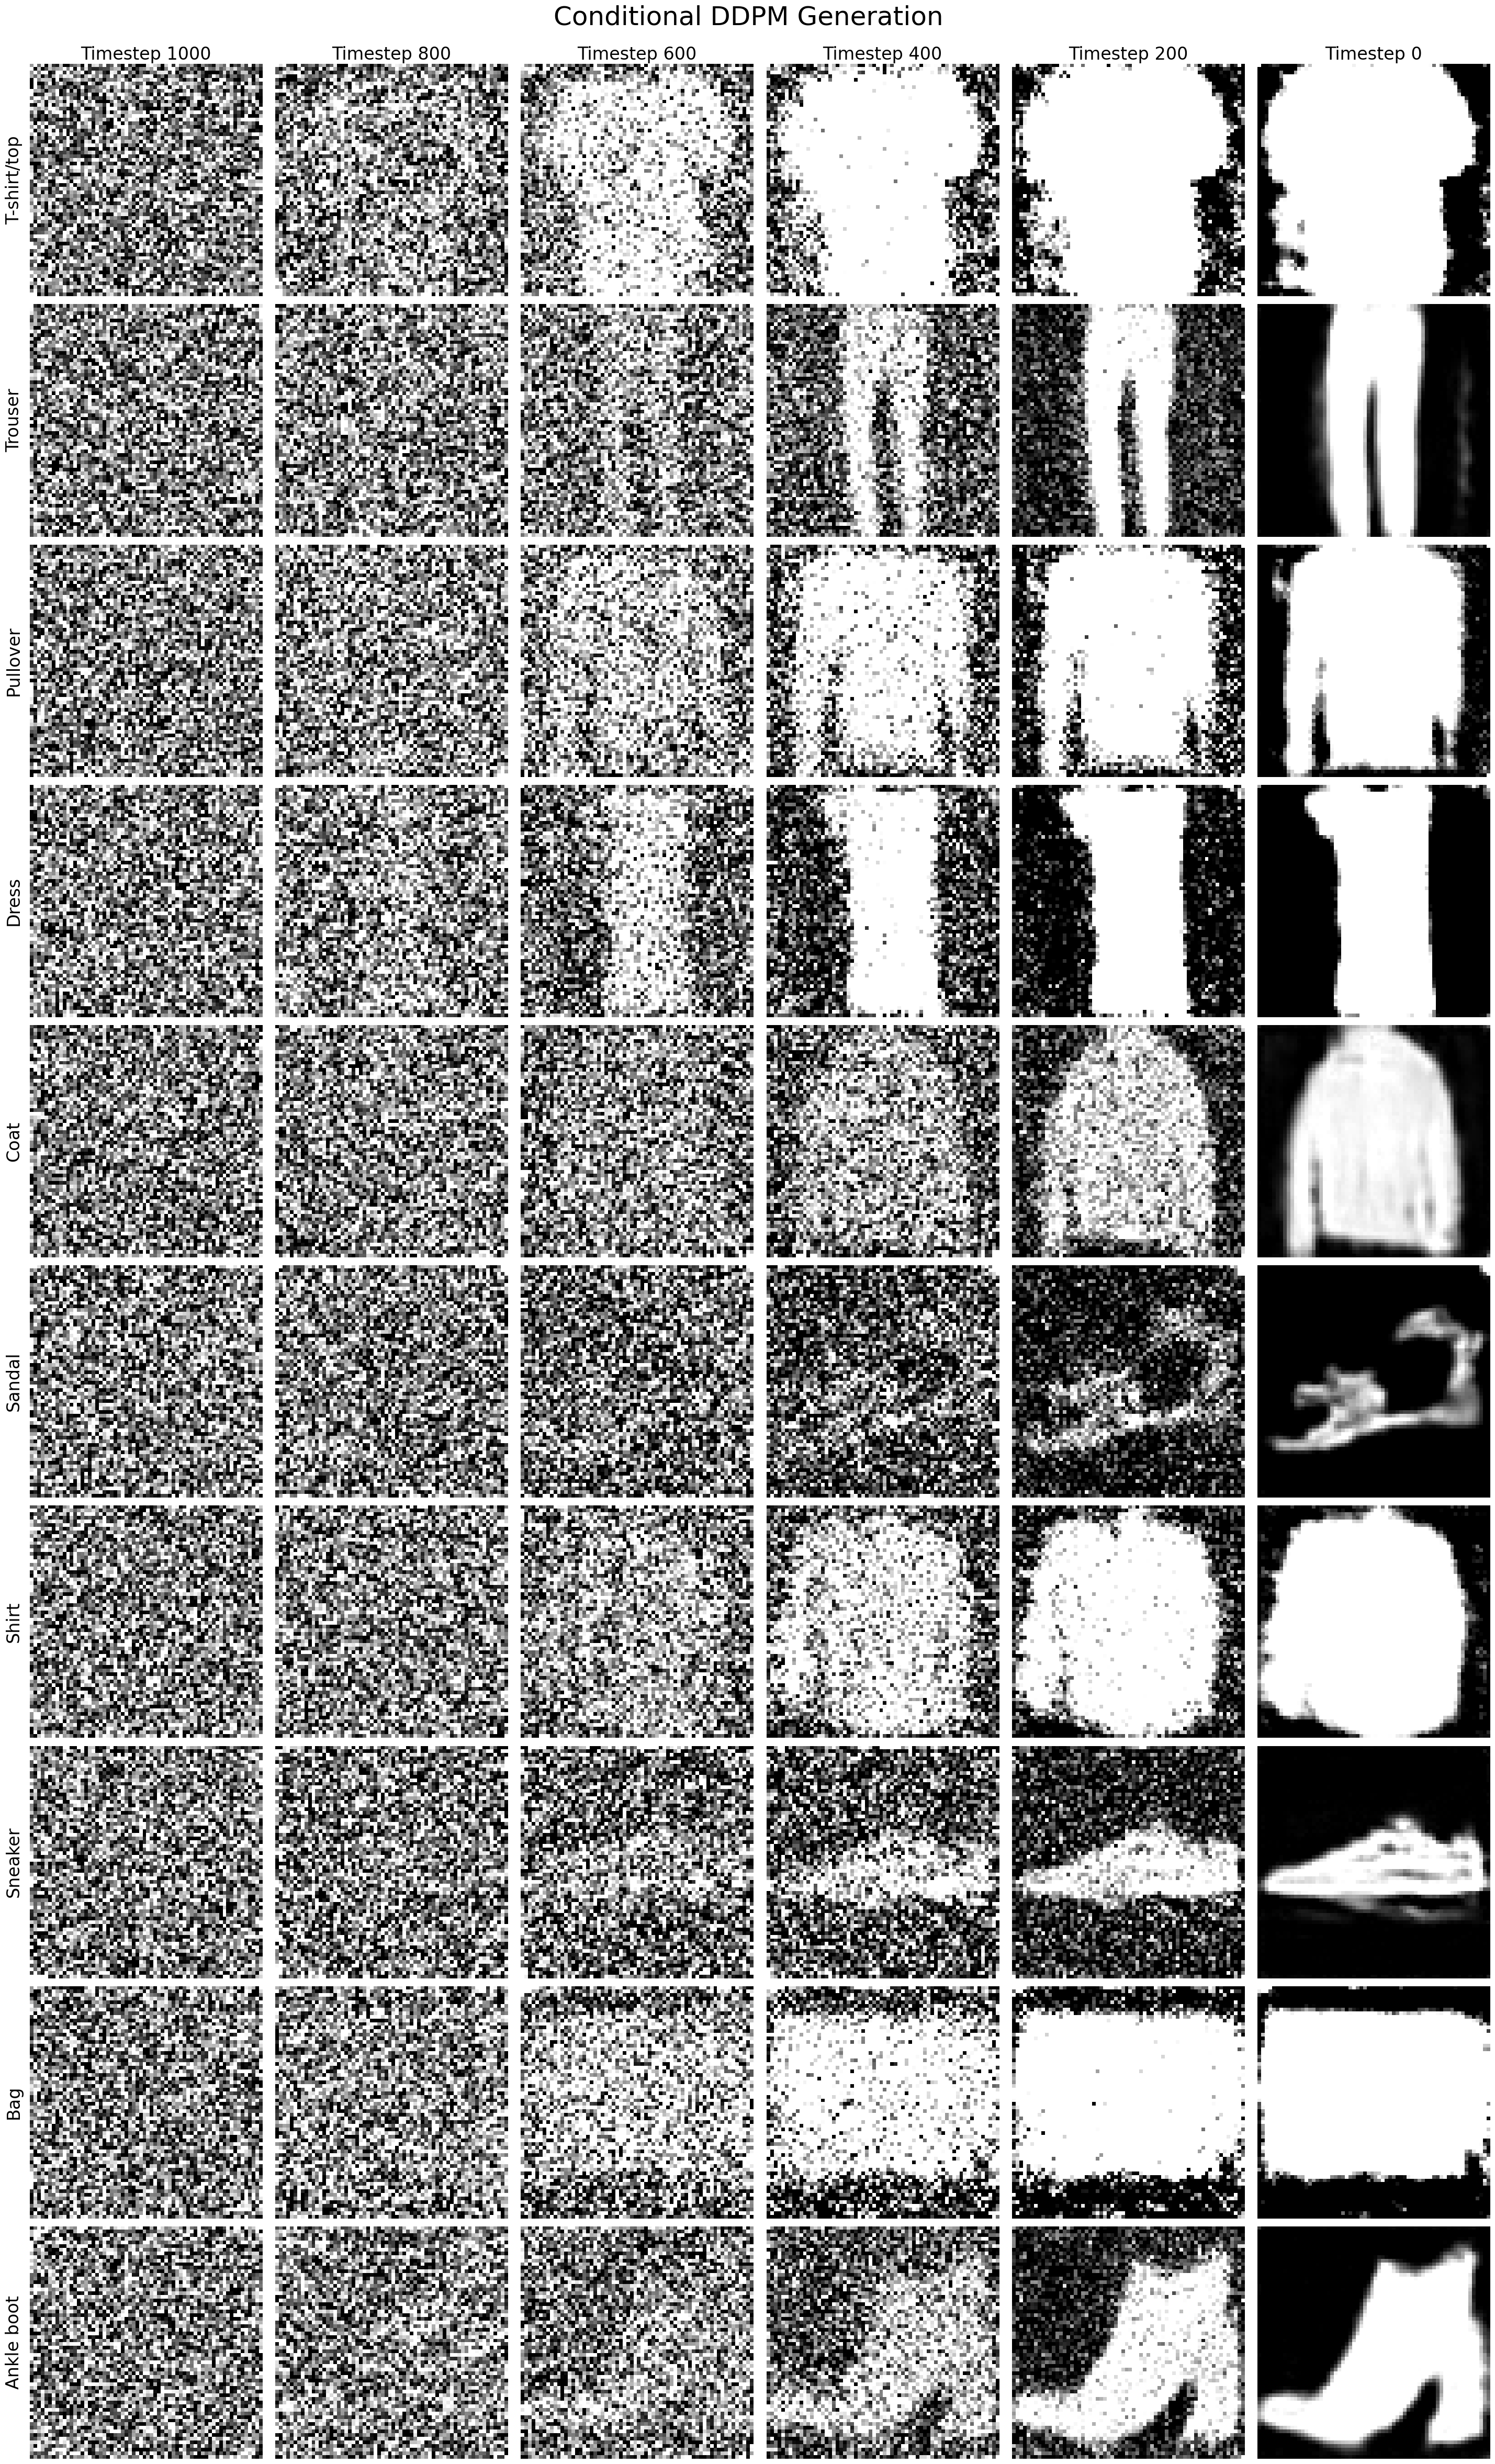

In [54]:
fig, axes = plt.subplots(
    n_samples,
    len(intermediates),
    figsize=(4.8 * len(intermediates), 4.8 * n_samples)
)

fig.suptitle('Conditional DDPM Generation', size=36)

for col, (timestep, img) in enumerate(intermediates):
    for row in range(n_samples):
        ax = axes[row, col]

        if col == 0:
            class_name = class_names[target_classes[row]]
            ax.set_ylabel(class_name, fontsize=24, labelpad=10)
        ax.imshow(img[row, 0].cpu().numpy(), cmap='gray')
        if row == 0:
            ax.set_title(f'Timestep {timestep}', size=24)

        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.savefig('ddpm_samples.png')
plt.show()